In [1]:
import numpy as np
import matplotlib.pyplot as plt

from data_preparation import (
    load_data,
    split_data,
    scale_features,
    feature_dist,
    feature_pair,
)

from nn_pipeline import (
    initialize_parameters,
    sigmoid,
    sigmoid_derivative,
    softmax,
    forward_propagation,
    compute_loss,
    backward_propagation,
    update_parameters,
    predict,
    accuracy_score,
    train_model,
)

from eval_analysis import (
    evaluate_model,
    plot_pca_decision_boundaries,
    compare_with_sklearn_mlp,
)

from experiment_analysis import (
    run_experiments,
    show_best_results,
)

class_names = ["setosa", "versicolor", "virginica"]

In [2]:
df = load_data()

display(df.head())
print("Dataset shape:", df.shape)
display(df.describe())
print("\nMissing values:\n", df.isnull().sum())
print("\nClass distribution:\n", df["Target"].value_counts().sort_index())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Target               0
dtype: int64

Class distribution:
 Target
0    50
1    50
2    50
Name: count, dtype: int64


In [3]:
import warnings
warnings.filterwarnings("ignore")

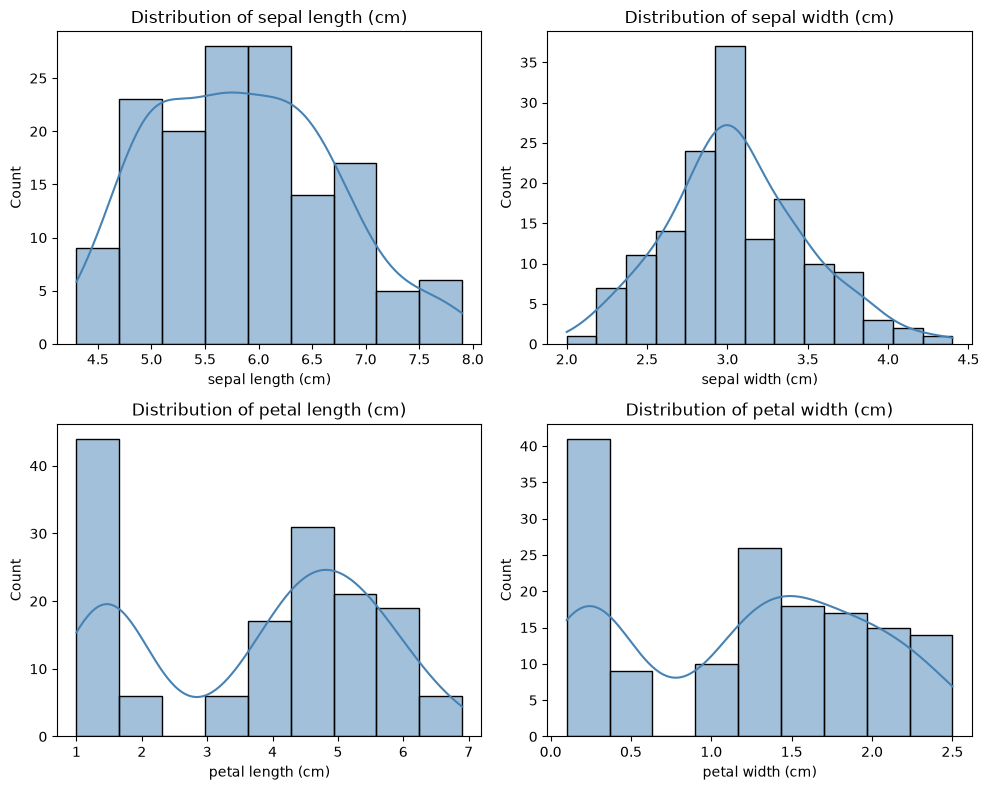

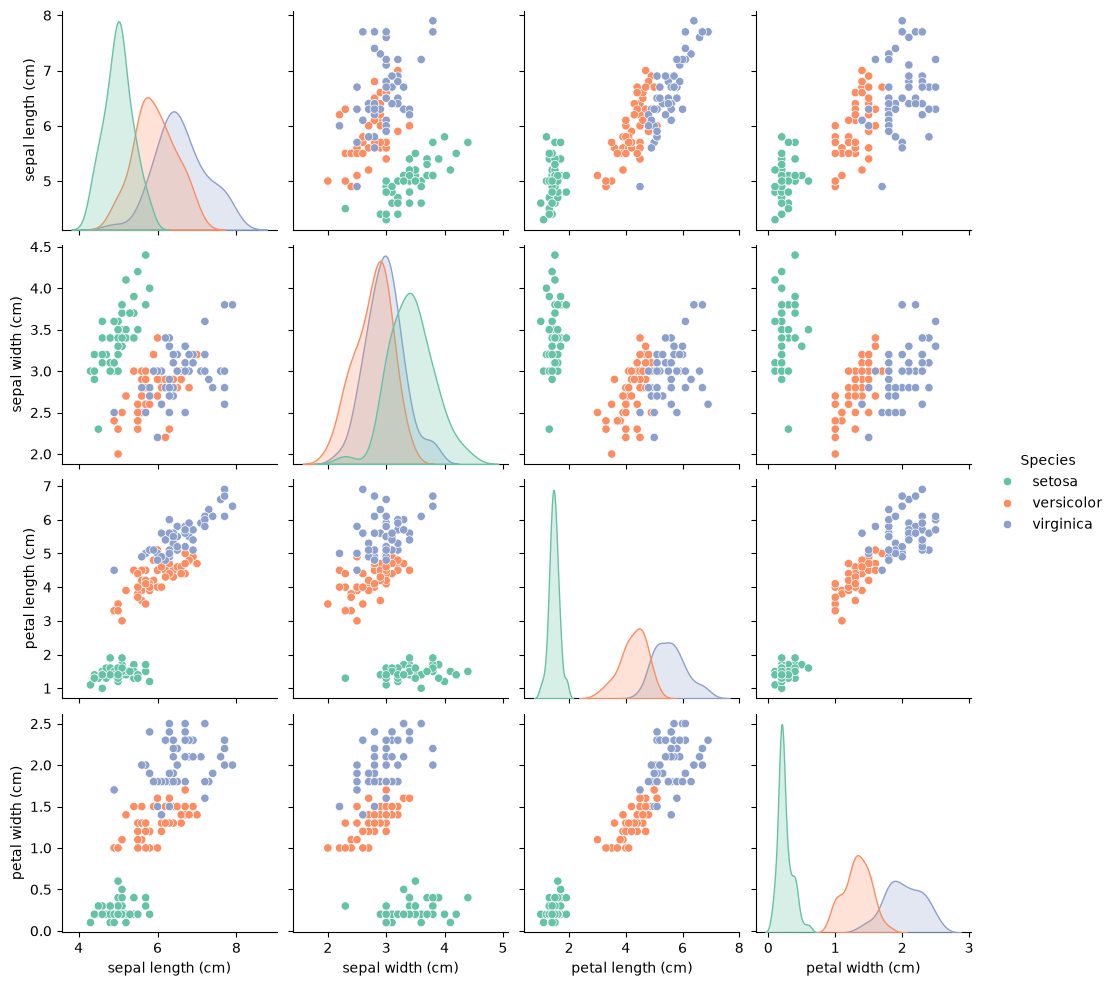

In [4]:
feature_dist(df.drop(columns=["Target"]))

iris_plot = df.copy()
iris_plot["Species"] = iris_plot["Target"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica",
})
feature_pair(
    iris_plot.drop(columns=["Target"]),
    hue="Species"
)

In [5]:
X_train, X_val, X_test, y_train, y_val, y_test = split_data(df)

X_train, X_val, X_test, scaler = scale_features(
    X_train, X_val, X_test
)

X_train = X_train.to_numpy(dtype=np.float64)
X_val = X_val.to_numpy(dtype=np.float64)
X_test = X_test.to_numpy(dtype=np.float64)

y_train = np.asarray(y_train, dtype=np.float64)
y_val = np.asarray(y_val, dtype=np.float64)
y_test = np.asarray(y_test, dtype=np.float64)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

========== Data Split Summary ==========
Train:      104 samples (69.3%) | y shape: (104, 3)
Validation: 23 samples (15.3%) | y shape: (23, 3)
Test:       23 samples (15.3%) | y shape: (23, 3)
X_train: (104, 4)
y_train: (104, 3)
X_val: (23, 4)
X_test: (23, 4)


In [6]:
params = initialize_parameters(n_x=4, n_h1= 8, n_h2=6, n_y= 3)

y_pred, cache = forward_propagation(X_train[:16], params)

print("Prediction shape:", y_pred.shape)
print("First prediction:", y_pred[0])
print("Probability sum:", y_pred[0].sum())

loss = compute_loss(y_train[:16], y_pred)
grads = backward_propagation(
    parameters=params, cache=cache, y_true=y_train[:16]
)

print("Initial loss:", loss)
print("Gradient keys:", grads.keys())

Prediction shape: (16, 3)
First prediction: [0.34979535 0.28672032 0.36348432]
Probability sum: 1.0
Initial loss: 1.1098021461729541
Gradient keys: dict_keys(['dW1', 'db1', 'dW2', 'db2', 'dW3', 'db3'])


In [7]:
params, history = train_model(
    X_train,
    y_train,
    X_val,
    y_val,
    n_h1=8,
    n_h2=6,
    learning_rate=0.01,
    epochs=1000,
    batch_size=16,
    patience=10,
    seed=42,
)

Epoch   50 | Loss: 1.0968 | Validation Accuracy: 0.3478
Epoch  100 | Loss: 1.0833 | Validation Accuracy: 0.4783
Epoch  150 | Loss: 1.0670 | Validation Accuracy: 0.6522
Epoch  200 | Loss: 1.0440 | Validation Accuracy: 0.6522
Epoch  250 | Loss: 1.0097 | Validation Accuracy: 0.6522
Epoch  300 | Loss: 0.9592 | Validation Accuracy: 0.6522
Epoch  350 | Loss: 0.8914 | Validation Accuracy: 0.6957
Epoch  400 | Loss: 0.8122 | Validation Accuracy: 0.7391
Epoch  450 | Loss: 0.7335 | Validation Accuracy: 0.8261
Epoch  500 | Loss: 0.6645 | Validation Accuracy: 0.8261
Epoch  550 | Loss: 0.6084 | Validation Accuracy: 0.8261
Epoch  600 | Loss: 0.5639 | Validation Accuracy: 0.8261
Epoch  650 | Loss: 0.5287 | Validation Accuracy: 0.8261
Epoch  700 | Loss: 0.5003 | Validation Accuracy: 0.8261
Epoch  750 | Loss: 0.4768 | Validation Accuracy: 0.8696
Epoch  800 | Loss: 0.4566 | Validation Accuracy: 0.9130
Epoch  850 | Loss: 0.4389 | Validation Accuracy: 0.9130
Epoch  900 | Loss: 0.4229 | Validation Accuracy:

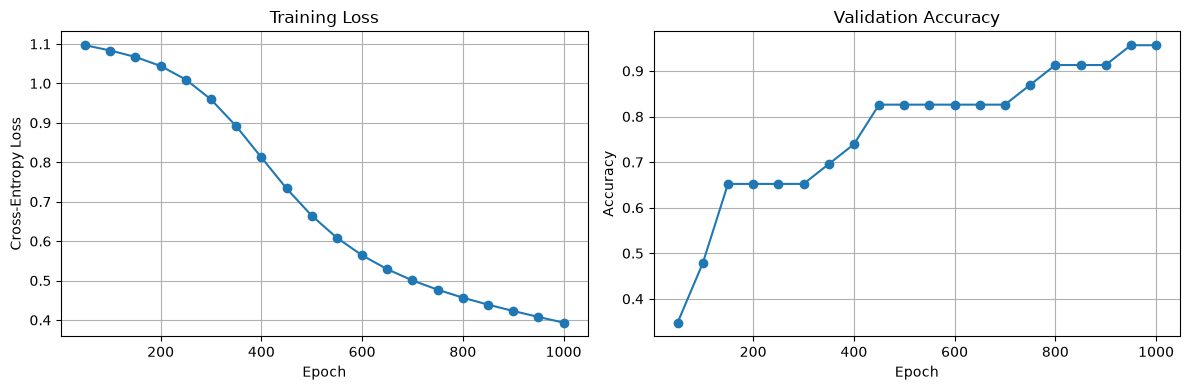

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epochs"], history["loss"], marker="o")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True)

axes[1].plot(history["epochs"], history["val_accuracy"], marker="o")
axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [9]:
test_predictions = predict(X_test, params)

test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Test accuracy: 0.7826
Test accuracy: 78.26%


Test Accuracy: 0.782608695652174

Classification Report:
              precision    recall  f1-score   support

      Setosa       0.78      1.00      0.88         7
  Versicolor       1.00      0.38      0.55         8
   Virginica       0.73      1.00      0.84         8

    accuracy                           0.78        23
   macro avg       0.84      0.79      0.75        23
weighted avg       0.84      0.78      0.75        23



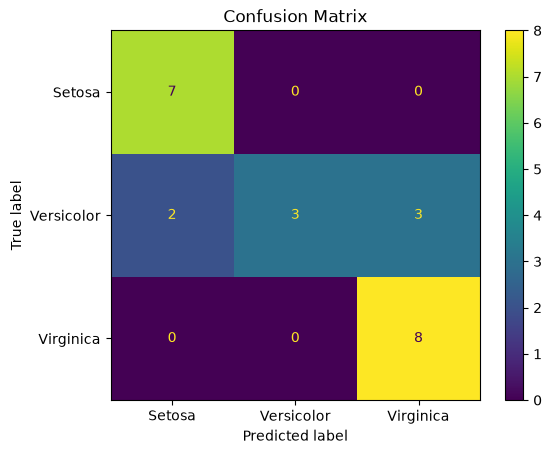

In [10]:
accuracy, cm = evaluate_model(X_test, y_test, params, predict)

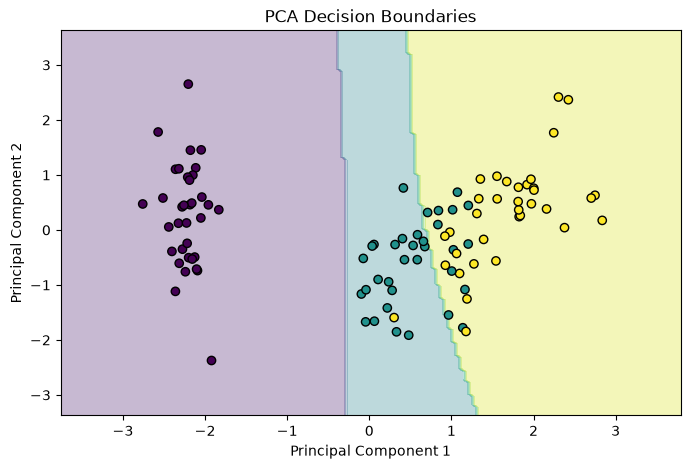

In [11]:
plot_pca_decision_boundaries(X_train, y_train, params, predict)

In [12]:
results, mlp = compare_with_sklearn_mlp(
    X_train, y_train,
    X_val, y_val,
    X_test, y_test,
    params, predict
)

                   Model  Training Accuracy  Validation Accuracy  \
0  Custom Neural Network           0.884615             0.956522   
1            Sklearn MLP           0.971154             1.000000   

   Test Accuracy  
0       0.782609  
1       0.956522  


In [13]:
results = run_experiments(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
)

display(results)

,Experiment,Setting,Train Accuracy,Validation Accuracy,Test Accuracy
0,Learning Rate,0.001,0.326923,0.347826,0.347826
1,Learning Rate,0.01,0.336538,0.304348,0.347826
2,Learning Rate,0.1,0.980769,1.000000,0.956522
3,Activation,relu,0.971154,1.000000,0.913043
4,Activation,tanh,0.971154,1.000000,0.956522
5,Activation,logistic,0.336538,0.304348,0.347826
6,Architecture,"(6,)",0.961538,1.000000,0.913043
7,Architecture,"(8, 6)",0.336538,0.304348,0.347826
8,Architecture,"(12, 8, 6)",0.336538,0.347826,0.304348


In [14]:
best_results = show_best_results(results)

Best results for each experiment:
   Experiment Setting  Train Accuracy  Validation Accuracy  Test Accuracy
   Activation    relu        0.971154                  1.0       0.913043
 Architecture    (6,)        0.961538                  1.0       0.913043
Learning Rate     0.1        0.980769                  1.0       0.956522
